In [1]:
!pip -q install lifelines

import re, itertools
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from lifelines import KaplanMeierFitter
from lifelines.statistics import logrank_test, multivariate_logrank_test
from IPython.display import display

  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done


In [2]:
from google.colab import files

COHORT = "Burgmaier"            # First reproduce Burgmaier's four-class curves
PLOT_END_YEAR = 18              # Same x-axis limit as AA709_1837.ipynb
OUTPUT_DIR = Path('/content/PKHD1_four_class_figures')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

CSV_PATHS = {
    'Burgmaier': Path('/content/Burgmaier_Genotype_Phenotype_Replication - Burgmaier_S3_Source (2).csv'),
    'NephVar': Path('/content/NephVar Database - PKHD1 (5).csv'),
}

if not CSV_PATHS[COHORT].is_file():
    print(f'Upload this file: {CSV_PATHS[COHORT].name}')
    files.upload()

assert CSV_PATHS[COHORT].is_file(), f'Missing input CSV at {CSV_PATHS[COHORT]}'
for name, path in CSV_PATHS.items():
    print(f'{name:10s}: {path} ({"found" if path.is_file() else "not uploaded"})')

Burgmaier : /content/Burgmaier_Genotype_Phenotype_Replication - Burgmaier_S3_Source (2).csv (found)
NephVar   : /content/NephVar Database - PKHD1 (5).csv (found)


In [3]:
!pip -q install lifelines

import re
from pathlib import Path
from itertools import combinations
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from lifelines import KaplanMeierFitter, CoxPHFitter
from lifelines.statistics import multivariate_logrank_test, logrank_test
from statsmodels.stats.multitest import multipletests
from IPython.display import display
from google.colab import files

# Both cohorts are pooled; COHORT is not used to filter the data.
PLOT_END_YEAR = 18
OUTPUT_DIR = Path('/content/PKHD1_region_presence_4class')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
CSV_PATHS = {
    'Burgmaier': Path('/content/Burgmaier_Genotype_Phenotype_Replication - Burgmaier_S3_Source (2).csv'),
    'NephVar': Path('/content/NephVar Database - PKHD1 (6).csv'),
}
# Fall back to (5) only if (6) is not uploaded.
if not CSV_PATHS['NephVar'].exists():
    CSV_PATHS['NephVar'] = Path('/content/NephVar Database - PKHD1 (5).csv')

missing = [p.name for p in CSV_PATHS.values() if not p.is_file()]
if missing:
    print('Upload the missing files:', missing)
    files.upload()
for name, path in CSV_PATHS.items():
    assert path.is_file(), f'Missing input CSV at {path}'
    print(f'{name:10s}: {path.name}')


Burgmaier : Burgmaier_Genotype_Phenotype_Replication - Burgmaier_S3_Source (2).csv
NephVar   : NephVar Database - PKHD1 (5).csv


In [4]:
# CELL 2 — Pool cases, keep both alleles, and assign 4 exclusive carrier groups.
KNOWN = {'Null','Mis1-708','Mis709-1837','Mis1838-2624','Mis2625-4074'}
GROUP_ORDER = ['AA709–1837 only', 'AA1–708 only', 'Mixed', 'Neither']
COLORS = {
    'AA709–1837 only': '#8e44ad',  # purple
    'AA1–708 only':    '#2980b9',  # blue
    'Mixed':           '#e58b37',  # orange
    'Neither':         '#888888',  # gray
}

def age_number(value):
    match = re.match(r'^\s*([+-]?(?:\d+(?:\.\d*)?|\.\d+))', str(value))
    return float(match.group(1)) if match else np.nan

def find_column(data, prefix):
    matches = [c for c in data.columns if c.lower().startswith(prefix.lower())]
    if len(matches) != 1:
        raise KeyError(f'Expected one column beginning with {prefix!r}, found {matches}')
    return matches[0]

records, exclusions = [], []
for cohort, path in CSV_PATHS.items():
    source = pd.read_csv(path, dtype=str).dropna(subset=['Predicted protein change'])
    krt_col = find_column(source, 'KRT (')
    fu_col = find_column(source, 'Last follow-')
    for idx, r in source.iterrows():
        raw_class = str(r['Functional class'])
        alleles = re.sub(r'\s+', '', raw_class).split('/')
        if len(alleles) != 2 or not set(alleles).issubset(KNOWN):
            exclusions.append({'Cohort':cohort, 'CSV row':idx+2,
                               'Functional class':raw_class, 'Reason':'Unclassified or complex alleles'})
            continue
        has709 = 'Mis709-1837' in alleles
        has1 = 'Mis1-708' in alleles
        if has709 and has1: group = 'Mixed'
        elif has709: group = 'AA709–1837 only'
        elif has1: group = 'AA1–708 only'
        else: group = 'Neither'

        age_krt = age_number(r[krt_col])
        fu_text = str(r[fu_col])
        age_fu = age_number(fu_text)
        event = int(np.isfinite(age_krt))
        duration = age_krt if event else age_fu
        # Time-zero KRT is retained as an event at a numerically small positive age.
        if event and duration <= 0: duration = 0.001
        # Do not infer censoring from a missing/zero follow-up.
        if not event and np.isfinite(duration) and duration <= 0: duration = np.nan
        if 'terminat' in fu_text.lower(): duration = np.nan
        records.append({
            'Cohort':cohort, 'CSV row':idx+2, 'Functional class':raw_class,
            'Allele 1':alleles[0], 'Allele 2':alleles[1],
            'has709':int(has709), 'has1':int(has1),
            'null_count':alleles.count('Null'),
            'null_null':int(alleles == ['Null', 'Null']),
            'Group':group, 'KRT age':age_krt, 'Last follow-up age':age_fu,
            'duration':duration, 'event':event,
            'Conflict':int(event and np.isfinite(age_fu) and age_krt > age_fu + 1e-9)
        })

all_genotypes = pd.DataFrame(records)
km = all_genotypes.loc[all_genotypes.duration.notna()].copy()
km['Group'] = pd.Categorical(km['Group'], categories=GROUP_ORDER, ordered=True)
exclusions = pd.DataFrame(exclusions)

print('Pooled, unambiguous two-allele genotypes:',len(all_genotypes))
print('KRT-eligible patients:',len(km),' | events:',int(km.event.sum()))
print('Excluded uncertain genotypes:',len(exclusions))
print('Event age later than reported follow-up:',int(km.Conflict.sum()))
display(km.groupby('Group', observed=False)['event'].agg(N='size', Events='sum').reindex(GROUP_ORDER))
print('By source cohort:')
display(pd.crosstab(km['Group'],km['Cohort']).reindex(GROUP_ORDER))
if km.Conflict.any():
    display(km.loc[km.Conflict.eq(1), ['Cohort','CSV row','Group','KRT age','Last follow-up age']])

km.to_csv(OUTPUT_DIR/'patient_level_four_groups.csv', index=False)
exclusions.to_csv(OUTPUT_DIR/'excluded_uncertain_genotypes.csv',index=False)


Pooled, unambiguous two-allele genotypes: 503
KRT-eligible patients: 438  | events: 84
Excluded uncertain genotypes: 130
Event age later than reported follow-up: 2


,N,Events
Group,,
AA709–1837 only,143,16
AA1–708 only,116,30
Mixed,24,5
Neither,155,33


By source cohort:


Cohort,Burgmaier,NephVar
Group,,
AA709–1837 only,71,72
AA1–708 only,71,45
Mixed,16,8
Neither,64,91


,Cohort,CSV row,Group,KRT age,Last follow-up age
13,Burgmaier,15,Neither,0.04,0.0
33,Burgmaier,44,Neither,1.45,0.5


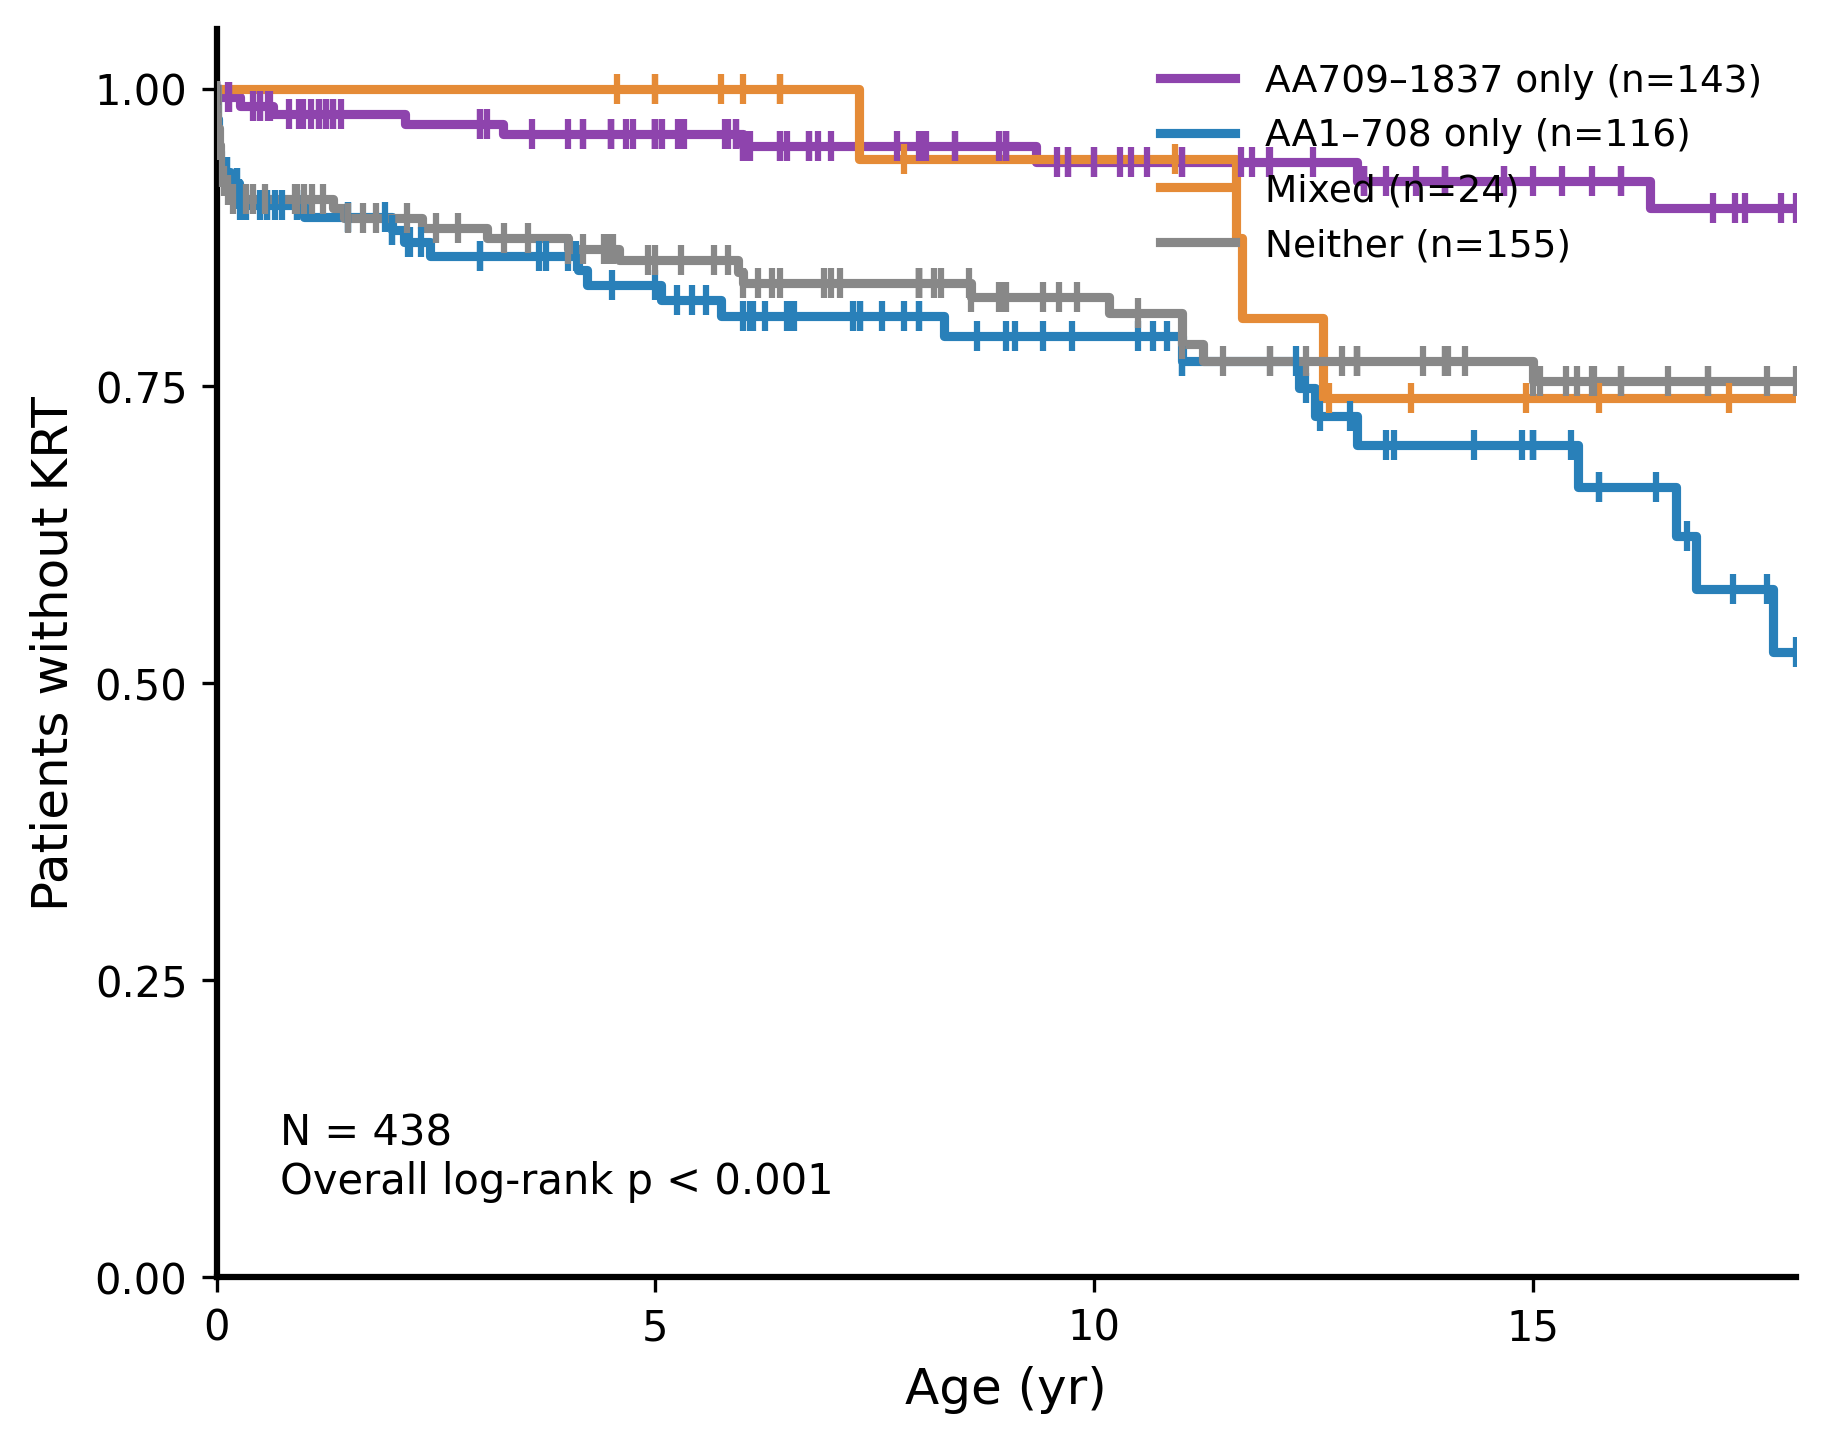

Overall four-group log-rank chi2 = 17.2058 p = 0.0006410982319507094
Number at risk:


Year,0,5,10,15
Group,,,,
AA709–1837 only,143,106,69,46
AA1–708 only,116,67,41,24
Mixed,24,23,15,8
Neither,155,91,63,44


Pairwise log-rank tests:


,Group 1,Group 2,p_raw,p_Holm_6
0,AA709–1837 only,AA1–708 only,0.000009,0.000056
1,AA709–1837 only,Mixed,0.273711,0.547423
2,AA709–1837 only,Neither,0.008730,0.043651
3,AA1–708 only,Mixed,0.107084,0.428335
4,AA1–708 only,Neither,0.140673,0.428335
5,Mixed,Neither,0.632539,0.632539


In [5]:
# CELL 3 — Kaplan-Meier: 4 mutually exclusive groups.
plt.rcParams.update({
    'font.family':'DejaVu Sans','font.size':11,
    'axes.linewidth':1.5, 'axes.spines.top':False, 'axes.spines.right':False,
    'figure.dpi':300, 'figure.facecolor':'none','axes.facecolor':'none'
})

fig, ax = plt.subplots(figsize=(6.5,5.2))
fig.subplots_adjust(left=.16,right=.97,top=.95,bottom=.15)
risk_rows = []
for group in GROUP_ORDER:
    s = km.loc[km.Group.eq(group)].copy()
    fit = KaplanMeierFitter().fit(s.duration, s.event, label=f'{group} (n={len(s)})')
    fit.plot_survival_function(ax=ax,ci_show=False,linewidth=2.2,color=COLORS[group])
    cens = s.loc[s.event.eq(0),'duration'].to_numpy()
    if len(cens):
        ax.scatter(cens,fit.survival_function_at_times(cens).to_numpy(),
                   marker='|',s=50,lw=1.5,color=COLORS[group],zorder=4)
    for year in [0,5,10,15]:
        risk_rows.append({'Group':group,'Year':year,'At risk':int((s.duration >= year).sum())})

overall = multivariate_logrank_test(km.duration,km.Group,km.event)
pvalue = 'p < 0.001' if overall.p_value < .001 else f'p = {overall.p_value:.3f}'
ax.text(.04,.06,f'N = {len(km)}\nOverall log-rank {pvalue}',
        transform=ax.transAxes,fontsize=10,va='bottom')
ax.set_xlim(0,PLOT_END_YEAR)
ax.set_ylim(0,1.05)
ax.set_xticks([0,5,10,15])
ax.set_yticks([0,.25,.50,.75,1])
ax.yaxis.set_major_formatter(ticker.FormatStrFormatter('%.2f'))
ax.set_xlabel('Age (yr)',fontsize=12)
ax.set_ylabel('Patients without KRT',fontsize=12)
ax.legend(loc='upper right',frameon=False,fontsize=9)
ax.tick_params(axis='both',labelsize=10)
fig.savefig(OUTPUT_DIR/'KM_KRT_4_carrier_groups.png',dpi=300,bbox_inches='tight',transparent=True)
fig.savefig(OUTPUT_DIR/'KM_KRT_4_carrier_groups.pdf',bbox_inches='tight',transparent=True)
plt.show()

print('Overall four-group log-rank chi2 =',round(overall.test_statistic,4),'p =',overall.p_value)
print('Number at risk:')
display(pd.DataFrame(risk_rows).pivot(index='Group',columns='Year',values='At risk').reindex(GROUP_ORDER))

# All 6 exploratory pairwise log-rank tests, Holm-adjusted.
rows = []
for a,b in combinations(GROUP_ORDER,2):
    aa=km.loc[km.Group.eq(a)]; bb=km.loc[km.Group.eq(b)]
    result=logrank_test(aa.duration,bb.duration,aa.event,bb.event)
    rows.append({'Group 1':a,'Group 2':b,'p_raw':result.p_value})
comparison=pd.DataFrame(rows)
comparison['p_Holm_6']=multipletests(comparison.p_raw,method='holm')[1]
print('Pairwise log-rank tests:')
display(comparison)
comparison.to_csv(OUTPUT_DIR/'KM_pairwise_Holm.csv',index=False)


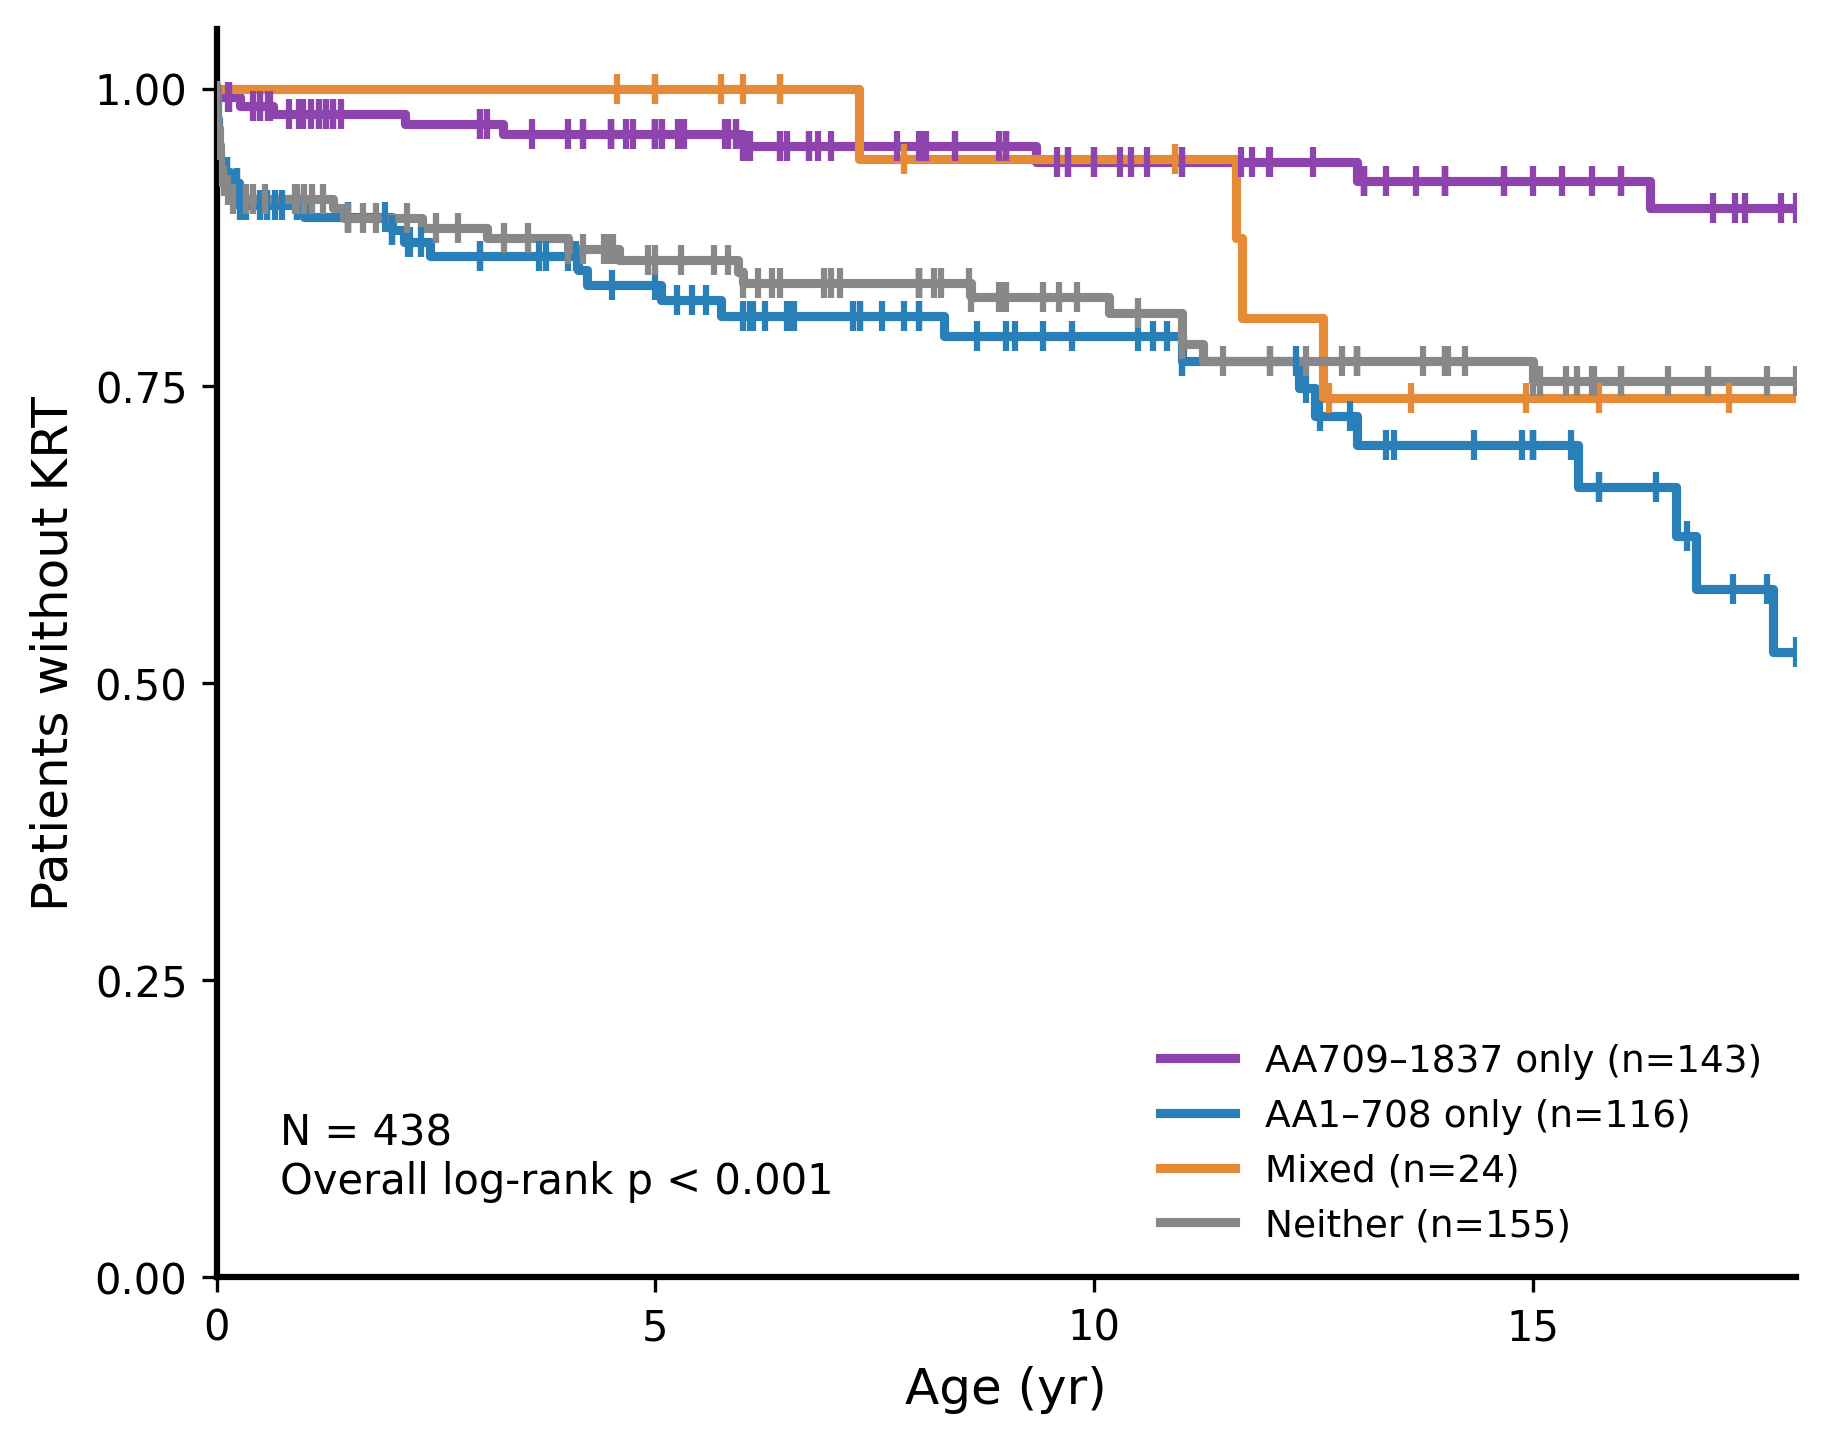

Overall four-group log-rank chi2 = 17.2058 p = 0.0006410982319507094
Number at risk:


Year,0,5,10,15
Group,,,,
AA709–1837 only,143,106,69,46
AA1–708 only,116,67,41,24
Mixed,24,23,15,8
Neither,155,91,63,44


Pairwise log-rank tests:


,Group 1,Group 2,p_raw,p_Holm_6
0,AA709–1837 only,AA1–708 only,0.000009,0.000056
1,AA709–1837 only,Mixed,0.273711,0.547423
2,AA709–1837 only,Neither,0.008730,0.043651
3,AA1–708 only,Mixed,0.107084,0.428335
4,AA1–708 only,Neither,0.140673,0.428335
5,Mixed,Neither,0.632539,0.632539


In [7]:

# CELL 3 — Kaplan-Meier: 4 mutually exclusive groups.

plt.rcParams.update({
    'font.family':'DejaVu Sans','font.size':11,
    'axes.linewidth':1.5, 'axes.spines.top':False, 'axes.spines.right':False,
    'figure.dpi':300, 'figure.facecolor':'none','axes.facecolor':'none'
})

fig, ax = plt.subplots(figsize=(6.5,5.2))
fig.subplots_adjust(left=.16,right=.97,top=.95,bottom=.15)

risk_rows = []

for group in GROUP_ORDER:
    s = km.loc[km.Group.eq(group)].copy()

    fit = KaplanMeierFitter().fit(
        s.duration,
        s.event,
        label=f'{group} (n={len(s)})'
    )

    fit.plot_survival_function(
        ax=ax,
        ci_show=False,
        linewidth=2.2,
        color=COLORS[group]
    )

    cens = s.loc[s.event.eq(0), 'duration'].to_numpy()

    if len(cens):
        ax.scatter(
            cens,
            fit.survival_function_at_times(cens).to_numpy(),
            marker='|',
            s=50,
            lw=1.5,
            color=COLORS[group],
            zorder=4
        )

    for year in [0,5,10,15]:
        risk_rows.append({
            'Group':group,
            'Year':year,
            'At risk':int((s.duration >= year).sum())
        })

# Overall log-rank test
overall = multivariate_logrank_test(
    km.duration,
    km.Group,
    km.event
)

pvalue = (
    'p < 0.001'
    if overall.p_value < .001
    else f'p = {overall.p_value:.3f}'
)

ax.text(
    .04, .06,
    f'N = {len(km)}\nOverall log-rank {pvalue}',
    transform=ax.transAxes,
    fontsize=10,
    va='bottom'
)

# Axes
ax.set_xlim(0, PLOT_END_YEAR)
ax.set_ylim(0, 1.05)

ax.set_xticks([0,5,10,15])
ax.set_yticks([0,.25,.50,.75,1])

ax.yaxis.set_major_formatter(
    ticker.FormatStrFormatter('%.2f')
)

ax.set_xlabel('Age (yr)', fontsize=12)
ax.set_ylabel('Patients without KRT', fontsize=12)

# Legend — bottom right
ax.legend(
    loc='lower right',
    frameon=False,
    fontsize=9
)

ax.tick_params(axis='both', labelsize=10)

# Save figures
fig.savefig(
    OUTPUT_DIR/'KM_KRT_4_carrier_groups.png',
    dpi=300,
    bbox_inches='tight',
    transparent=True
)

fig.savefig(
    OUTPUT_DIR/'KM_KRT_4_carrier_groups.pdf',
    bbox_inches='tight',
    transparent=True
)

plt.show()

# Overall statistics
print(
    'Overall four-group log-rank chi2 =',
    round(overall.test_statistic,4),
    'p =',
    overall.p_value
)

print('Number at risk:')

display(
    pd.DataFrame(risk_rows)
    .pivot(index='Group', columns='Year', values='At risk')
    .reindex(GROUP_ORDER)
)

# All 6 exploratory pairwise log-rank tests, Holm-adjusted.
rows = []

for a,b in combinations(GROUP_ORDER,2):

    aa = km.loc[km.Group.eq(a)]
    bb = km.loc[km.Group.eq(b)]

    result = logrank_test(
        aa.duration,
        bb.duration,
        aa.event,
        bb.event
    )

    rows.append({
        'Group 1':a,
        'Group 2':b,
        'p_raw':result.p_value
    })

comparison = pd.DataFrame(rows)

comparison['p_Holm_6'] = multipletests(
    comparison.p_raw,
    method='holm'
)[1]

print('Pairwise log-rank tests:')
display(comparison)

comparison.to_csv(
    OUTPUT_DIR/'KM_pairwise_Holm.csv',
    index=False
)


Cohort-stratified Cox regression


,exp(coef),exp(coef) lower 95%,exp(coef) upper 95%,p
covariate,,,,
AA709–1837 only,0.435946,0.239494,0.793545,0.006595
AA1–708 only,1.231814,0.736961,2.058950,0.426352
Mixed,0.623971,0.241561,1.611768,0.329999


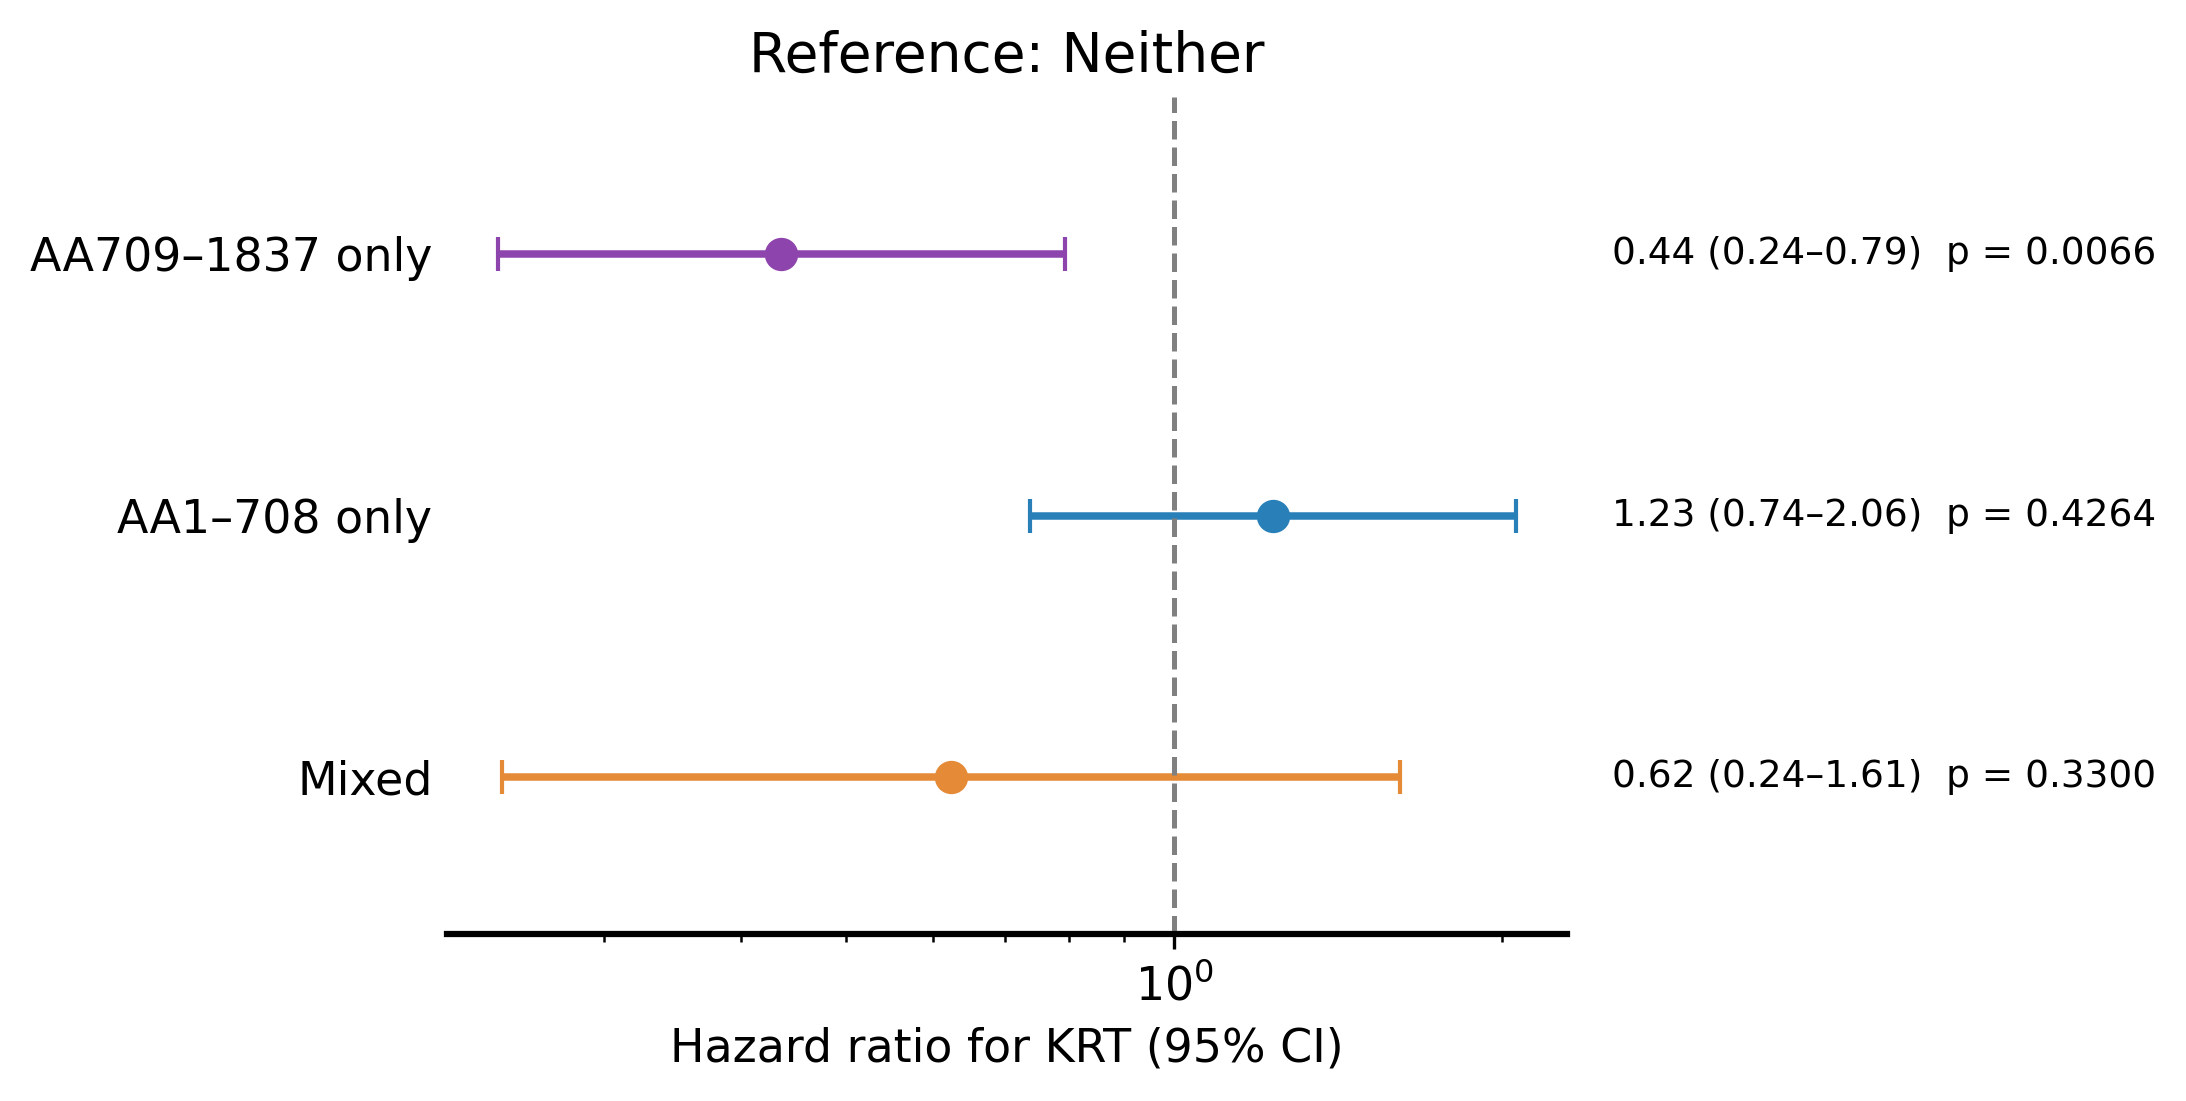

In [8]:

# ==========================================================
# COX REGRESSION — FOUR CARRIER GROUPS
# Reference: Neither
# ==========================================================

COX_GROUPS = [
    "AA709–1837 only",
    "AA1–708 only",
    "Mixed"
]

cox_df = km[
    ["duration", "event", "Cohort", "Group", "null_count"]
].copy()

for group in COX_GROUPS:
    cox_df[group] = (
        cox_df["Group"] == group
    ).astype(int)

cph = CoxPHFitter()

cph.fit(
    cox_df[
        ["duration", "event", "Cohort"] + COX_GROUPS
    ],
    duration_col="duration",
    event_col="event",
    strata=["Cohort"]
)

results = cph.summary.loc[COX_GROUPS].copy()

print("Cohort-stratified Cox regression")
display(results[[
    "exp(coef)",
    "exp(coef) lower 95%",
    "exp(coef) upper 95%",
    "p"
]])

# ----------------------------------------------------------
# Forest plot
# ----------------------------------------------------------

fig, ax = plt.subplots(figsize=(7.5, 3.8), dpi=300)

y = [2, 1, 0]

for pos, group in zip(y, COX_GROUPS):

    row = results.loc[group]

    hr = row["exp(coef)"]
    low = row["exp(coef) lower 95%"]
    high = row["exp(coef) upper 95%"]
    p = row["p"]

    ax.errorbar(
        hr, pos,
        xerr=[[hr-low], [high-hr]],
        fmt="o",
        color=COLORS[group],
        ecolor=COLORS[group],
        markersize=7,
        elinewidth=1.8,
        capsize=4
    )

    label = (
        f"{hr:.2f} ({low:.2f}–{high:.2f})  "
        f"p = {p:.4f}"
    )

    ax.text(
        1.04, pos, label,
        transform=ax.get_yaxis_transform(),
        va="center",
        fontsize=9,
        clip_on=False
    )

ax.axvline(
    1, color="gray",
    linestyle="--", linewidth=1.2
)

ax.set_yticks(y)
ax.set_yticklabels(COX_GROUPS)

ax.set_xscale("log")
ax.set_xlabel("Hazard ratio for KRT (95% CI)")
ax.set_title("Reference: Neither")

ax.set_ylim(-0.6, 2.6)

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", length=0)
ax.grid(False)

fig.tight_layout()

fig.savefig(
    OUTPUT_DIR / "Cox_four_region_carrier_groups.png",
    dpi=300, transparent=True, bbox_inches="tight"
)

plt.show()
